In [4]:
import pandas as pd
from datasets import load_dataset

In [11]:
!pip install -U huggingface_hub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 857.0/857.0 kB 12.6 MB/s  0:00:00
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface_hub 1.33.0
    Uninstalling huggingface_hub-1.33.0:
      Successfully uninstalled huggingface_hub-1.33.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.4.0 which is incompatible.


In [1]:
from huggingface_hub import login

login()

In [5]:

df = pd.read_parquet("hf://datasets/mitulshah/transaction-categorization/default/train/0000.parquet")
df

,transaction_description,category,country,currency
0,Wage,Income,USA,USD
1,Arby's (Contactless),Food & Dining,AUSTRALIA,AUD
2,Occupational Therapy,Healthcare & Medical,USA,USD
3,Potbelly Store Branch,Food & Dining,UK,GBP
4,Amazon - AUSTRALIA,Shopping & Retail,AUSTRALIA,AUD
...,...,...,...,...
4501038,Point of Sale Shopping,Shopping & Retail,USA,USD
4501039,Dining Out - Thai Restaurant,Food & Dining,USA,USD
4501040,500.00,Shopping & Retail,USA,USD
4501041,Dining Out - Sushi Restaurant,Food & Dining,USA,USD


In [8]:
# 1. Quantidade de descrições únicas
total = len(df)
unique = df["transaction_description"].nunique()

print(f"Total de registros: {total:,}")
print(f"Descrições únicas: {unique:,}")
print(f"Percentual de descrições únicas: {unique / total:.2%}")

# 2. Descrições mais frequentes
print("\nDescrições mais frequentes:")
print(df["transaction_description"].value_counts().head(20))

# 3. Quantidade de registros por categoria
print("\nCategorias:")
print(df["category"].value_counts())

# 4. Exemplos aleatórios de cada categoria
for category in df["category"].unique():
    print(f"\n--- {category} ---")

    examples = (
        df.loc[df["category"] == category, "transaction_description"]
        .sample(n=5, random_state=42)
    )

    for description in examples:
        print(description)

Total de registros: 4,501,043
Descrições únicas: 1,387,044
Percentual de descrições únicas: 30.82%

Descrições mais frequentes:
transaction_description
Payroll            5660
Salary             5421
Temple             5170
Social Security    5070
Frontier           4575
Post Office        4571
CVS                4570
Walgreens          4552
Rite Aid           4542
Target             4100
Subway             3972
Dividend           2864
Income             2808
Maternity Leave    2784
Rental Income      2781
Gig Work           2758
Royalty            2758
Reward             2755
SPCA               2744
Capital Gains      2732
Name: count, dtype: int64

Categorias:
category
Utilities & Services          451842
Government & Legal            451108
Financial Services            450959
Income                        450545
Charity & Donations           450133
Shopping & Retail             449941
Healthcare & Medical          449857
Entertainment & Recreation    449495
Transportation          

In [9]:
# Quantas categorias diferentes cada descrição possui?
description_stats = (
    df.groupby("transaction_description")
    .agg(
        total=("category", "size"),
        categories=("category", "nunique")
    )
)

# Descrições associadas a mais de uma categoria
conflicting = description_stats[
    description_stats["categories"] > 1
]

print("Descrições com categorias conflitantes:",
      len(conflicting))

print("Percentual sobre descrições únicas:",
      len(conflicting) / df["transaction_description"].nunique())

print("\nExemplos de conflitos:")

examples = conflicting.head(20).index

print(
    df[df["transaction_description"].isin(examples)]
    .sort_values("transaction_description")
    .to_string(index=False)
)

Descrições com categorias conflitantes: 2485
Percentual sobre descrições únicas: 0.0017915797912683375

Exemplos de conflitos:
transaction_description             category   country currency
                    CVS Healthcare & Medical     INDIA      INR
                    CVS Healthcare & Medical    CANADA      CAD
                    CVS Healthcare & Medical        UK      GBP
                    CVS    Shopping & Retail        UK      GBP
                    CVS    Shopping & Retail    CANADA      CAD
                    CVS Healthcare & Medical    CANADA      CAD
                    CVS Healthcare & Medical    CANADA      CAD
                    CVS Healthcare & Medical       USA      USD
                    CVS    Shopping & Retail AUSTRALIA      AUD
                    CVS    Shopping & Retail    CANADA      CAD
                    CVS    Shopping & Retail AUSTRALIA      AUD
                    CVS Healthcare & Medical     INDIA      INR
                    CVS Healthcare & Medi

In [10]:
print("Valores ausentes:")
print(df.isna().sum())

print("\nLinhas completamente duplicadas:")
print(df.duplicated().sum())

print("\nDescrições vazias:")
print(
    df["transaction_description"]
    .str.strip()
    .eq("")
    .sum()
)

Valores ausentes:
transaction_description    0
category                   0
country                    0
currency                   0
dtype: int64

Linhas completamente duplicadas:
2940825

Descrições vazias:
0


In [12]:
df_clean = df.drop_duplicates().copy()

print(f"Original: {len(df):,}")
print(f"Após deduplicação: {len(df_clean):,}")

Original: 4,501,043
Após deduplicação: 1,560,218


In [13]:
from sklearn.model_selection import train_test_split

X = df_clean["transaction_description"]
y = df_clean["category"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Treinamento:", len(X_train))
print("Teste:", len(X_test))

Treinamento: 1248174
Teste: 312044


In [14]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            strip_accents="unicode",
            ngram_range=(1, 2),
            min_df=2,
            max_features=100_000
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            solver="lbfgs"
        )
    )
])

In [15]:
model.fit(X_train, y_train)

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=100000, min_df=2,
                                 ngram_range=(1, 2), strip_accents='unicode')),
                ('classifier', LogisticRegression(max_iter=1000))])

Accuracy: 0.9893444514235172

Relatório de classificação:
                            precision    recall  f1-score   support

       Charity & Donations       1.00      1.00      1.00     30727
Entertainment & Recreation       1.00      1.00      1.00     31441
        Financial Services       1.00      1.00      1.00     31188
             Food & Dining       1.00      0.99      0.99     31627
        Government & Legal       0.99      0.98      0.99     31250
      Healthcare & Medical       0.98      0.97      0.98     31155
                    Income       0.99      1.00      0.99     30439
         Shopping & Retail       0.95      0.97      0.96     31540
            Transportation       1.00      0.99      0.99     31662
      Utilities & Services       0.99      1.00      0.99     31015

                  accuracy                           0.99    312044
                 macro avg       0.99      0.99      0.99    312044
              weighted avg       0.99      0.99      0.9

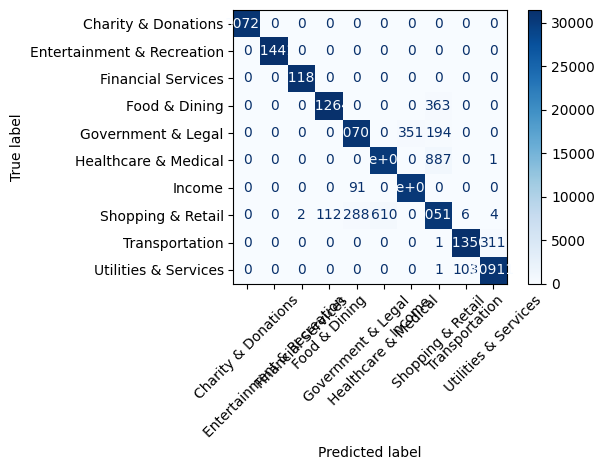

In [16]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nRelatório de classificação:")
print(classification_report(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation=45,
    cmap="Blues"
)

plt.tight_layout()
plt.show()

In [17]:
examples = [
    "UBER TRIP",
    "NETFLIX.COM",
    "WALMART PURCHASE",
    "PIX RECEBIDO JOAO",
    "SPOTIFY PREMIUM",
    "GROCERY STORE"
]

predictions = model.predict(examples)
probabilities = model.predict_proba(examples)

for description, prediction, probability in zip(
    examples,
    predictions,
    probabilities
):
    confidence = probability.max()

    print(
        f"{description:25} -> "
        f"{prediction:30} "
        f"(confiança: {confidence:.2%})"
    )

UBER TRIP                 -> Transportation                 (confiança: 100.00%)
NETFLIX.COM               -> Entertainment & Recreation     (confiança: 100.00%)
WALMART PURCHASE          -> Shopping & Retail              (confiança: 100.00%)
PIX RECEBIDO JOAO         -> Shopping & Retail              (confiança: 18.32%)
SPOTIFY PREMIUM           -> Entertainment & Recreation     (confiança: 100.00%)
GROCERY STORE             -> Shopping & Retail              (confiança: 73.96%)


In [18]:
vectorizer = model.named_steps["tfidf"]
classifier = model.named_steps["classifier"]

text = ["PIX RECEBIDO JOAO"]

vector = vectorizer.transform(text)

print("Quantidade de características reconhecidas:",
      vector.nnz)

print("Tamanho do vocabulário:",
      len(vectorizer.vocabulary_))

print("Probabilidades:")

probabilities = model.predict_proba(text)[0]

for category, probability in sorted(
    zip(classifier.classes_, probabilities),
    key=lambda x: x[1],
    reverse=True
):
    print(f"{category}: {probability:.2%}")

Quantidade de características reconhecidas: 0
Tamanho do vocabulário: 100000
Probabilidades:
Shopping & Retail: 18.32%
Transportation: 13.63%
Government & Legal: 10.33%
Food & Dining: 10.32%
Entertainment & Recreation: 8.59%
Healthcare & Medical: 8.11%
Charity & Donations: 7.83%
Utilities & Services: 7.66%
Financial Services: 7.62%
Income: 7.60%
